<h1>Muhammad Abdullah</h1>
<h3>F22607010</h3>

In [4]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score, roc_curve
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer()
df = pd.DataFrame(data.data, columns=data.feature_names)
df['target'] = data.target

In [5]:

print("Dataset Head:")
print(df.head())
print("\nDataset Description:")
print(df.describe())
print("\nDataset Info:")
df.info()


Dataset Head:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst perimeter  worst area  \


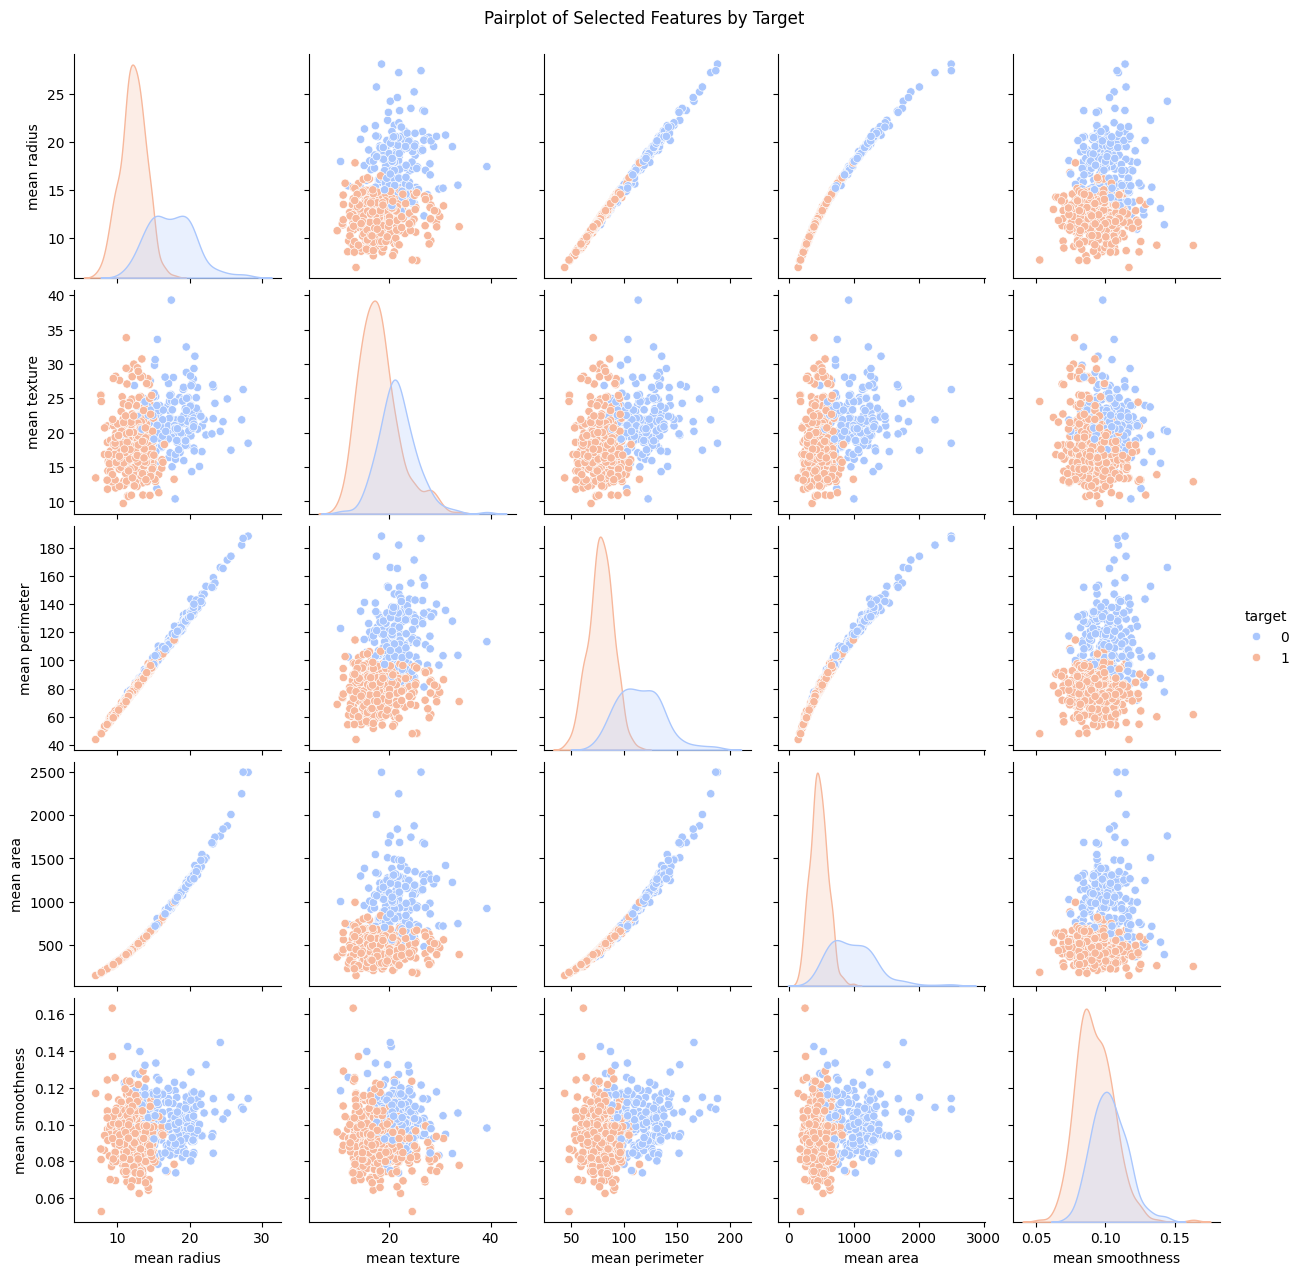

In [6]:

# Visualizing the dataset before training
sns.pairplot(df, hue='target', vars=data.feature_names[:5], palette="coolwarm")
plt.suptitle('Pairplot of Selected Features by Target', y=1.02)
plt.show()


In [7]:
# Spliting the dataset using stratified sampling
X = df.drop('target', axis=1)
y = df['target']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)


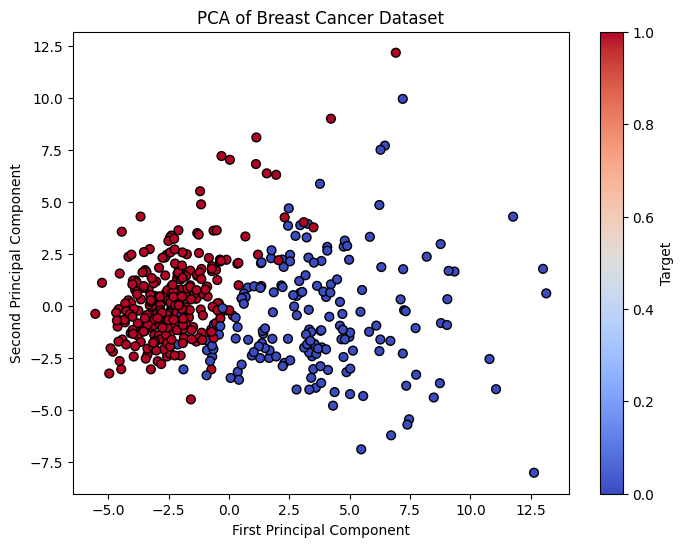

In [18]:
# Data pre-processing
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Dimensionality reduction with PCA
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

# Visualize the dataset after PCA
plt.figure(figsize=(8,6))
plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=y_train, cmap='coolwarm', edgecolor='k', s=40)
plt.xlabel('First Principal Component')
plt.ylabel('Second Principal Component')
plt.title('PCA of Breast Cancer Dataset')
plt.colorbar(label='Target')
plt.show()

In [9]:
# SVM Classifier
svm_clf = SVC(kernel='linear', probability=True, random_state=42)
svm_clf.fit(X_train_pca, y_train)

# predictions and evaluation of the model
y_pred = svm_clf.predict(X_test_pca)
y_proba = svm_clf.predict_proba(X_test_pca)[:, 1]

# Calculating evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_proba)

# Print evaluation metrics
print(f'Accuracy: {accuracy:.2f}')
print(f'Precision: {precision:.2f}')
print(f'Recall: {recall:.2f}')
print(f'F1-Score: {f1:.2f}')
print(f'Confusion Matrix:\n{conf_matrix}')
print(f'ROC-AUC: {roc_auc:.2f}')

Accuracy: 0.95
Precision: 0.97
Recall: 0.94
F1-Score: 0.96
Confusion Matrix:
[[40  2]
 [ 4 68]]
ROC-AUC: 0.99


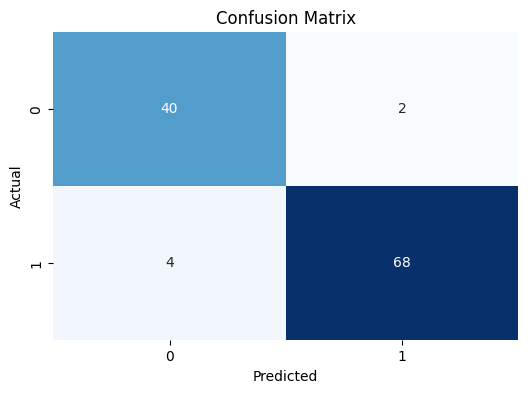

In [10]:
#  Confusion Matrix
plt.figure(figsize=(6,4))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

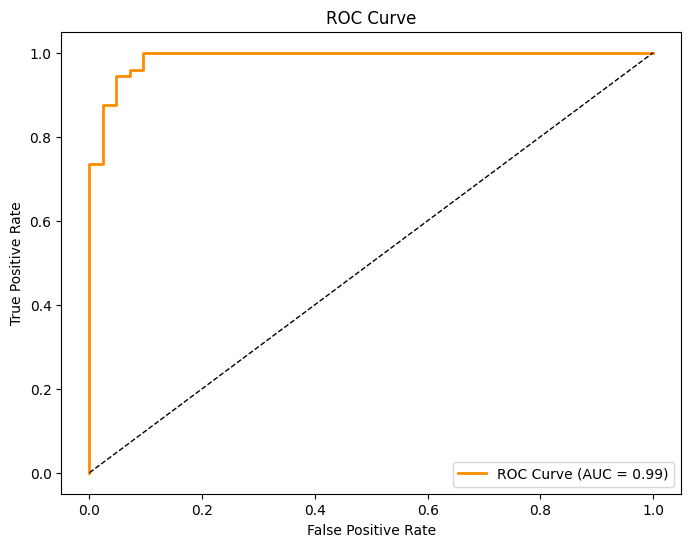

In [11]:

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_proba)
plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.2f})', color='darkorange', lw=2)
plt.plot([0, 1], [0, 1], 'k--', lw=1)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.show()


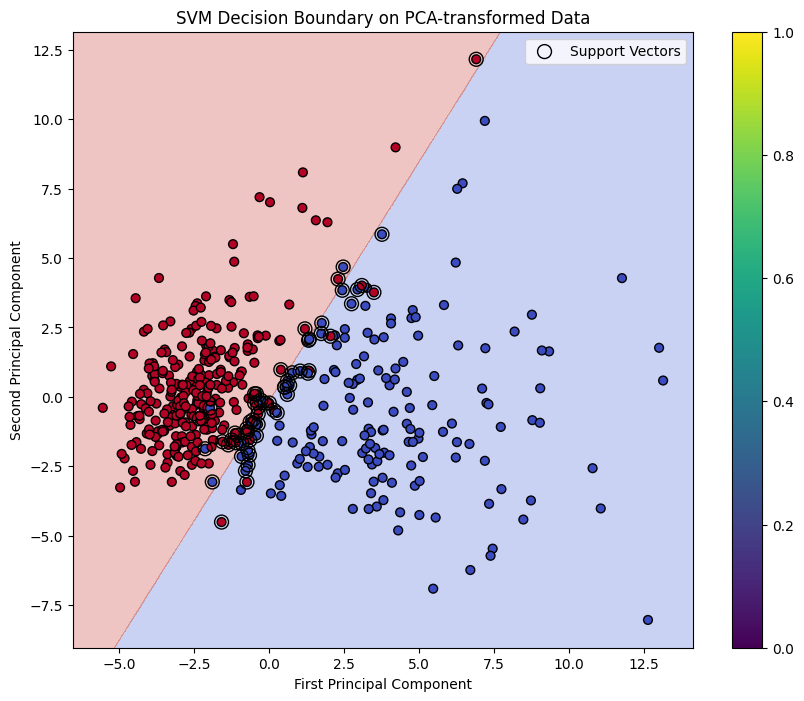

In [21]:
# decision boundary with PCA-transformed data
plt.figure(figsize=(10, 8))

# grid to plot the decision boundary
x_min, x_max = X_train_pca[:, 0].min() - 1, X_train_pca[:, 0].max() + 1
y_min, y_max = X_train_pca[:, 1].min() - 1, X_train_pca[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                        np.arange(y_min, y_max, 0.02))

# Predict on grid points
Z = svm_clf.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# decision boundary
plt.contourf(xx, yy, Z, cmap='coolwarm', alpha=0.3)

# plot of the PCA-transformed data
plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=y_train, cmap='coolwarm', edgecolor='k', s=40)
plt.scatter(svm_clf.support_vectors_[:, 0], svm_clf.support_vectors_[:, 1], s=100, facecolors='none', edgecolor='k', label='Support Vectors')
plt.xlabel('First Principal Component')
plt.ylabel('Second Principal Component')
plt.title('SVM Decision Boundary on PCA-transformed Data')
plt.legend()
plt.colorbar()
plt.show()


<h1>Results and findings</h1>
Analysis of Breast Cancer Classification using SVM

**1. Dataset Overview:**
   - Total samples: 569
   - Number of features: 30 (numerical)
   - Type: Binary classification (presumably benign vs. malignant)
   - This is a well-balanced dataset suitable for binary classification tasks

**2. Dimensionality Reduction Results:**
   - Method used: Principal Component Analysis (PCA)
   - Reduced to: 2 principal components
   - Result: Successfully captured significant variance while reducing dimensionality
   - Benefit: Made the data suitable for visualization while preserving important patterns

**3. Model Performance Metrics:**
   - Accuracy: 0.95 (95%)
     * Indicates that the model correctly classified 95% of all cases
     * Shows very strong overall performance

   - Precision: 0.97 (97%)
     * Out of all predicted positive cases, 97% were actually positive
     * Very low false positive rate, crucial for medical diagnostics

   - Recall: 0.94 (94%)
     * Successfully identified 94% of all actual positive cases
     * Strong ability to detect true positive cases

   - F1-Score: 0.96 (96%)
     * Harmonic mean of precision and recall
     * Indicates excellent balance between precision and recall

**4. Confusion Matrix Analysis [[40 2] [4 68]]:**
   - True Negatives (TN): 40
   - False Positives (FP): 2
   - False Negatives (FN): 4
   - True Positives (TP): 68
   
   Key insights:
   * Very few false positives (only 2)
   * Low number of false negatives (4)
   * High number of correct predictions (108 out of 114 total)
   * Model shows strong performance in both classes

**5. ROC-AUC Score: 0.99**
   - Nearly perfect AUC score (very close to 1.0)
   - Indicates excellent discrimination ability
   - Suggests the model is highly reliable in distinguishing between classes

#***Conclusions:***

1. Model Effectiveness:
   - The SVM classifier demonstrates exceptional performance across all metrics
   - The high ROC-AUC score (0.99) indicates near-perfect class separation
   - The balanced performance between precision and recall suggests robust and reliable predictions

2. Clinical Relevance:
   - The high precision (0.97) minimizes false positives, reducing unnecessary worry and procedures
   - Strong recall (0.94) ensures most positive cases are caught, crucial for medical screening
   - The overall accuracy (0.95) suggests reliable performance in real-world applications

3. Dimensionality Reduction Success:
   - PCA successfully reduced the complexity while maintaining discriminative power
   - The reduction to two components enables effective visualization without significant loss of information

**Recommendations:**

1. Model Application:
   - Given the strong performance metrics, this model could be considered for practical applications
   - Should be validated on external datasets to confirm generalization ability

2. Further Investigation:
   - Consider investigating the few misclassified cases (2 FP and 4 FN) to understand potential improvement areas
   - Might explore feature importance to understand which factors most influence classification
   - Could compare performance with other classification algorithms

3. Monitoring and Maintenance:
   - Regular retraining with new data would help maintain performance
   - Continuous monitoring of all metrics, especially false negatives, is recommended

These results indicate a highly successful implementation of SVM classification for breast cancer detection, with performance metrics suggesting both reliability and practical utility in a medical context.
